# ESMFold2 — Distant internal repeats


## 1. Data source/acquisition

Query experimental PDB protein entities first released2021-10-01 through2026-05-26, length289–336 and resolution≤3.5Å, from X-ray or electron-microscopy experiments. Download their canonical sequences and metadata. Exclude PDB entries named in all nine FoldBench target lists at commit4273f6877d82bd0b2fa476d1b2f34d121cbccc70 and the six large-complex examples in paper Figure S14. Build the sequence-reference corpus from entries released strictly before2021-09-30. Public responses and software binaries are fingerprinted. The input population is the current public response to these explicit fixed-date queries; the actual counts are printed.


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter,defaultdict
import os,json,hashlib,urllib.request,subprocess,tarfile,io,time,socket,math,re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
os.environ['OMP_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2'
ROOT=Path(os.environ.get('ESMFOLD_CODEX_R2_ROOT',str(Path.cwd()/'calculations/codex-r2'))).resolve();ROOT.mkdir(parents=True,exist_ok=True)
RAW=ROOT/'source_data';RAW.mkdir(exist_ok=True)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return known
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    with urllib.request.urlopen(request,timeout=180) as response,temporary.open('wb') as stream:
        headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
        while True:
            block=response.read(1024*1024)
            if not block:break
            stream.write(block)
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return record

TEST=2;AXIS='repeat';TARGET_PER_LEVEL=40;TITLE='Distant internal repeats'


In [2]:
import gzip
def request_json(url,payload,name):
    path=RAW/(name+'.json');receipt=path.with_suffix('.receipt.json')
    query_sha=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    if path.exists() and receipt.exists():
        record=json.loads(receipt.read_text())
        if record['query_sha256']!=query_sha or record['response_sha256']!=sha256_file(path):raise ValueError('Cached API response binding differs')
        return json.loads(path.read_text())
    request=urllib.request.Request(url,data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(4):
        try:
            with urllib.request.urlopen(request,timeout=180) as response:data=json.load(response)
            break
        except Exception:
            if attempt==3:raise
            time.sleep(2)
    path.write_text(json.dumps(data));receipt.write_text(json.dumps({'url':url,'query_sha256':query_sha,'response_sha256':sha256_file(path)},indent=2))
    return data
GQL="""query($ids:[String!]!){entries(entry_ids:$ids){rcsb_id exptl{method} rcsb_entry_info{resolution_combined} rcsb_accession_info{deposit_date initial_release_date} polymer_entities{rcsb_id entity_poly{pdbx_seq_one_letter_code_can rcsb_sample_sequence_length rcsb_entity_polymer_type} rcsb_polymer_entity_container_identifiers{auth_asym_ids asym_ids} rcsb_entity_source_organism{ncbi_taxonomy_id ncbi_scientific_name} rcsb_polymer_entity{pdbx_number_of_molecules}}}}"""

def term(attribute,operator,value):return {'type':'terminal','service':'text','parameters':{'attribute':attribute,'operator':operator,'value':value}}
query={'type':'group','logical_operator':'and','nodes':[term('rcsb_accession_info.initial_release_date','greater_or_equal','2021-10-01'),term('rcsb_accession_info.initial_release_date','less_or_equal','2026-05-26'),term('entity_poly.rcsb_sample_sequence_length','range',{'from':289,'to':336}),term('rcsb_entry_info.resolution_combined','less_or_equal',3.5),{'type':'group','logical_operator':'or','nodes':[term('exptl.method','exact_match','X-RAY DIFFRACTION'),term('exptl.method','exact_match','ELECTRON MICROSCOPY')]}]}
entity_ids=[]
for start in range(0,100000,10000):
    response=request_json('https://search.rcsb.org/rcsbsearch/v2/query',{'query':query,'return_type':'polymer_entity','request_options':{'paginate':{'start':start,'rows':10000},'sort':[{'sort_by':'rcsb_id','direction':'asc'}]}},f'candidate_entities_postcutoff_{start:06}')
    entity_ids.extend(row['identifier'] for row in response.get('result_set',[]))
    if start+10000>=response['total_count']:break
if not entity_ids:raise ValueError('No eligible public protein entities')
entries=sorted({entity.split('_')[0] for entity in entity_ids});wanted=set(entity_ids);metadata=[]
for start in range(0,len(entries),50):
    response=request_json('https://data.rcsb.org/graphql',{'query':GQL,'variables':{'ids':entries[start:start+50]}},f'candidate_metadata_postcutoff_{start:05}')
    if response.get('errors'):raise ValueError(response['errors'])
    for entry in response['data']['entries']:
        if entry is None:continue
        resolution=(entry.get('rcsb_entry_info') or {}).get('resolution_combined') or []
        dates=entry.get('rcsb_accession_info') or {};method=(entry.get('exptl') or [{}])[0].get('method')
        for entity in entry.get('polymer_entities') or []:
            if entity['rcsb_id'] not in wanted:continue
            sequence_info=entity.get('entity_poly') or {};identifiers=entity.get('rcsb_polymer_entity_container_identifiers') or {}
            metadata.append({'candidate_id':entity['rcsb_id'],'pdb_id':entry['rcsb_id'],'sequence':sequence_info.get('pdbx_seq_one_letter_code_can'),'polymer_type':sequence_info.get('rcsb_entity_polymer_type'),'auth_asym_ids':identifiers.get('auth_asym_ids') or [],'experimental_method':method,'resolution_angstrom':resolution[0] if resolution else np.nan,'release_date':dates.get('initial_release_date'),'chain_multiplicity':len(identifiers.get('asym_ids') or [])})
metadata=pd.DataFrame(metadata)
if metadata.candidate_id.duplicated().any():raise ValueError('Duplicate source entities')
FOLDBENCH_REVISION='4273f6877d82bd0b2fa476d1b2f34d121cbccc70'
FOLDBENCH_TABLES=['interface_antibody_antigen','interface_protein_dna','interface_protein_ligand','interface_protein_peptide','interface_protein_protein','interface_protein_rna','monomer_dna','monomer_protein','monomer_rna']
foldbench_ids=set();exclusion_sources=[]
for name in FOLDBENCH_TABLES:
    url='https://raw.githubusercontent.com/BEAM-Labs/FoldBench/'+FOLDBENCH_REVISION+'/targets/'+name+'.csv'
    path=RAW/('foldbench_'+name+'.csv');exclusion_sources.append(acquire(url,path))
    targets=pd.read_csv(path)
    if 'pdb_id' not in targets:raise ValueError('Missing FoldBench identifier column')
    foldbench_ids.update(targets.pdb_id.str.split('-').str[0].str.upper())
# Figure S14, page52: https://doi.org/10.64898/2026.06.03.729735
PAPER_FIGURE_S14_IDS={'9D1U','9NFE','9LYQ','9M6X','9LDL','9KCV'}
excluded_ids=foldbench_ids|PAPER_FIGURE_S14_IDS
if not all(re.fullmatch('[1-9][A-Z0-9]{3}',entry) for entry in excluded_ids):raise ValueError('Malformed exclusion identifier')
excluded_candidates=metadata[metadata.pdb_id.isin(excluded_ids)].copy()
metadata=metadata[~metadata.pdb_id.isin(excluded_ids)].copy()
print('Excluded benchmark/example entities:',len(excluded_candidates),'from',len(excluded_ids),'PDB identifiers')
reference_entries=[]
for start in range(0,500000,10000):
    response=request_json('https://search.rcsb.org/rcsbsearch/v2/query',{'query':term('rcsb_accession_info.initial_release_date','less','2021-09-30'),'return_type':'entry','request_options':{'paginate':{'start':start,'rows':10000}}},f'reference_entries_{start:06}')
    reference_entries.extend(row['identifier'].upper() for row in response.get('result_set',[]))
    if start+10000>=response['total_count']:break
seqres_path=RAW/'pdb_seqres.txt.gz';acquire('https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz',seqres_path)
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True);MMSEQS=TOOLS/'mmseqs/bin/mmseqs'
if not MMSEQS.exists():
    archive=TOOLS/'mmseqs18.tar.gz';acquire('https://github.com/soedinglab/MMseqs2/releases/download/18-8cc5c/mmseqs-linux-avx2.tar.gz',archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
print('Public candidate entities:',len(metadata),'reference entries:',len(reference_entries))
print('Search implementation:',subprocess.check_output([str(MMSEQS),'version'],text=True).strip())


Excluded benchmark/example entities: 166 from 1528 PDB identifiers


Public candidate entities: 11602 reference entries: 182454
Search implementation: 8cc5ce367b5638c4306c2d7cfc652dd099a4643f


## 2. Data processing

Remove duplicate canonical sequences and40%-identity clusters with bidirectional80% coverage. Keep the best-resolution representative, with deterministic SHA256 tie breaking. Download experimental coordinates and require≥90% aligned sequence identity,≥80% query alignment coverage and≥80% resolved C-alpha coverage. Discovery entries precede2025; confirmation entries are later, with globally disjoint clusters.


In [3]:
import gemmi
from Bio.SeqUtils import seq3
from Bio.Align import PairwiseAligner
STD=set('ACDEFGHIKLMNPQRSTVWY')
metadata['sequence']=metadata.sequence.fillna('').str.replace('\n','',regex=False).str.upper().str.strip();metadata['sequence_length']=metadata.sequence.str.len()
metadata=metadata[metadata.polymer_type.eq('Protein')&metadata.sequence_length.between(289,336)&metadata.sequence.map(lambda sequence:bool(sequence) and set(sequence).issubset(STD))&metadata.auth_asym_ids.map(bool)&metadata.resolution_angstrom.le(3.5)].copy()
metadata['split']=np.where(metadata.release_date.lt('2025-01-01'),'discovery','confirmation')
metadata['selection_key']=metadata.candidate_id.map(lambda key:hashlib.sha256(('20260716:'+key).encode()).hexdigest())
metadata=metadata.sort_values(['resolution_angstrom','selection_key']).drop_duplicates('sequence').reset_index(drop=True)
QUERY=ROOT/'candidate_sequences.fasta';QUERY.write_text(''.join('>'+row.candidate_id+'\n'+row.sequence+'\n' for row in metadata.itertuples()))
cluster_prefix=ROOT/('cluster_'+sha256_file(QUERY)[:16]);cluster_path=Path(str(cluster_prefix)+'_cluster.tsv');cluster_receipt=Path(str(cluster_prefix)+'.receipt.json')
cluster_binding={'query_sha256':sha256_file(QUERY),'binary_sha256':sha256_file(MMSEQS),'minimum_identity':.4,'coverage':.8,'coverage_mode':0}
if not cluster_path.exists() or not cluster_receipt.exists() or json.loads(cluster_receipt.read_text()).get('binding')!=cluster_binding:
    subprocess.run([str(MMSEQS),'easy-cluster',str(QUERY),str(cluster_prefix),str(ROOT/('cluster_tmp_'+cluster_binding['query_sha256'][:16])),'--min-seq-id','0.4','-c','0.8','--cov-mode','0','--threads','2','-v','1'],check=True)
    cluster_receipt.write_text(json.dumps({'binding':cluster_binding,'output_sha256':sha256_file(cluster_path)}))
if sha256_file(cluster_path)!=json.loads(cluster_receipt.read_text())['output_sha256']:raise ValueError('Clustering output differs')
clusters=pd.read_csv(cluster_path,sep='\t',header=None,names=['cluster','candidate_id'])
if set(clusters.candidate_id)!=set(metadata.candidate_id):raise ValueError('Clustering does not cover the complete current input population')
metadata=metadata.merge(clusters,on='candidate_id',validate='one_to_one').sort_values(['resolution_angstrom','selection_key']).drop_duplicates('cluster').sort_values('selection_key').reset_index(drop=True)
CHAIN_DIR=ROOT/'experimental_chains';CHAIN_DIR.mkdir(exist_ok=True)
def read_chain(path,chain_id):
    model=gemmi.read_structure(str(path))[0];chain=model.find_chain(str(chain_id))
    if chain is None:return '',np.empty((0,3))
    sequence=[];coordinates=[]
    for residue in chain:
        aa=gemmi.find_tabulated_residue(residue.name).one_letter_code.upper()
        if aa not in STD:continue
        atoms=[atom for atom in residue if atom.name=='CA' and atom.altloc in ['\x00','A']]
        if atoms:
            atom=atoms[0];sequence.append(aa);coordinates.append([atom.pos.x,atom.pos.y,atom.pos.z])
    return ''.join(sequence),np.asarray(coordinates,float)
def write_ca_pdb(sequence,coordinates,path):
    lines=[]
    for i,(aa,xyz) in enumerate(zip(sequence,coordinates),1):
        x,y,z=xyz;lines.append(f'ATOM  {i:5d}  CA  {seq3(aa).upper():>3s} A{i:4d}    {x:8.3f}{y:8.3f}{z:8.3f}  1.00 50.00           C')
    Path(path).write_text('\n'.join(lines+['TER','END'])+'\n')
def download_entry(entry):
    path=RAW/(entry+'.cif.gz');acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',path);return entry
with ThreadPoolExecutor(max_workers=2) as pool:
    for number,entry in enumerate(pool.map(download_entry,sorted(set(metadata.pdb_id))),1):
        if number%100==0:print('Experimental structures acquired:',number,flush=True)
aligner=PairwiseAligner(mode='global');aligner.match_score=2;aligner.mismatch_score=-1;aligner.open_gap_score=-3;aligner.extend_gap_score=-.5
qc_rows=[]
for row in metadata.itertuples():
    chosen=None
    for chain_id in row.auth_asym_ids:
        sequence,coordinates=read_chain(RAW/(row.pdb_id+'.cif.gz'),chain_id)
        if not sequence:continue
        alignment=aligner.align(row.sequence,sequence)[0];pairs=[]
        for left,right in zip(*alignment.aligned):pairs.extend(zip(range(*left),range(*right)))
        matches=sum(row.sequence[left]==sequence[right] for left,right in pairs)
        identity=matches/len(pairs) if pairs else 0;coverage=len(pairs)/len(row.sequence);resolved=len(coordinates)/len(row.sequence)
        if identity>=.9 and coverage>=.8 and resolved>=.8:
            chosen=(chain_id,sequence,coordinates,identity,coverage,resolved);break
    if chosen is None:continue
    chain_id,sequence,coordinates,identity,coverage,resolved=chosen
    path=CHAIN_DIR/(row.candidate_id+'_target.pdb');write_ca_pdb(sequence,coordinates,path)
    qc_rows.append({'candidate_id':row.candidate_id,'target_chain_extracted':chain_id,'target_chain_path':str(path),'target_sequence_identity':identity,'target_alignment_coverage':coverage,'target_resolved_ca_fraction':resolved})
pool=metadata.merge(pd.DataFrame(qc_rows),on='candidate_id',validate='one_to_one')
pool['sequence_sha256']=pool.sequence.map(lambda sequence:hashlib.sha256(sequence.encode()).hexdigest())
print('Sequence-cluster representatives:',len(metadata),'coordinate-eligible:',len(pool));display(pool.groupby('split').size())


Experimental structures acquired: 100


Experimental structures acquired: 200


Experimental structures acquired: 300


Experimental structures acquired: 400


Experimental structures acquired: 500


Experimental structures acquired: 600


... (7 outputs left out)

Experimental structures acquired: 1400


Experimental structures acquired: 1500


Sequence-cluster representatives: 1666 coordinate-eligible: 1341


split
confirmation    494
discovery       847
dtype: int64

## 3. Axis definition and level construction

Calculate exact4-mer repeat coverage at separations≥24, normalized amino-acid entropy, dominant-residue fraction, charge, composition and12-residue low-complexity windows. Repeat levels are0,0.02–0.04,≥0.05; entropy thresholds are0.9329365/0.9504774 with lower entropy higher risk; multiplicity levels are1,2–3,≥4; dominance thresholds are0.1043496/0.1212767. Calculate pre-cutoff homology identity and coverage with MMseqs2. Order candidates by SHA256(seed20260716:entityID). For repeat/context and their discovery screen, choose high-risk anchors and minimum-cost matches on standardized input controls. For entropy/dominance, select the stated number independently within each level by that input-only order. The selected count and every assigned level are shown.


In [4]:
def sequence_features(sequence):
    n = len(sequence)
    counts = Counter(sequence)
    p = np.array(list(counts.values()), float) / n
    covered = np.zeros(n, dtype=bool)
    positions = defaultdict(list)
    for i in range(n - 3):
        positions[sequence[i:i + 4]].append(i)
    for starts in positions.values():
        if len(starts) < 2:
            continue
        for start in starts:
            if start - starts[0] >= 24 or starts[-1] - start >= 24:
                covered[start:start + 4] = True
    return {'sequence_length': n, 'normalized_sequence_entropy': float(-(p * np.log(p)).sum() / np.log(20)), 'distant_repeat4_coverage': float(covered.mean()), 'max_residue_fraction': max(counts.values()) / n, 'cysteine_fraction': counts['C'] / n, 'gly_pro_fraction': (counts['G'] + counts['P']) / n, 'hydrophobic_fraction': sum((counts[aa] for aa in 'AILMFWYV')) / n, 'net_charge_proxy': (counts['K'] + counts['R'] - counts['D'] - counts['E']) / n}
def low_complexity(sequence):
    marked=np.zeros(len(sequence),bool)
    for position in range(len(sequence)-11):
        counts=Counter(sequence[position:position+12]);entropy=-sum(count/12*math.log2(count/12) for count in counts.values())
        if entropy<2.2:marked[position:position+12]=True
    return float(marked.mean())
for column in sequence_features(pool.iloc[0].sequence):pool[column]=pool.sequence.map(lambda sequence:sequence_features(sequence)[column])
pool['low_complexity_fraction']=pool.sequence.map(low_complexity)
pool['method_X_ray']=pool.experimental_method.eq('X-RAY DIFFRACTION').astype(float)
REFERENCE=ROOT/'precutoff_sequences.fasta';precutoff=set(reference_entries)
with gzip.open(seqres_path,'rt') as source,REFERENCE.open('w') as destination:
    header=None;pieces=[]
    def emit_sequence(header,pieces):
        if header is None:return
        identifier=header.split()[0];sequence=''.join(pieces).upper()
        if identifier.split('_')[0].upper() in precutoff and 'mol:protein' in header and sequence and set(sequence).issubset(STD):destination.write('>'+identifier+'\n'+sequence+'\n')
    for line in source:
        if line.startswith('>'):emit_sequence(header,pieces);header=line[1:].strip();pieces=[]
        else:pieces.append(line.strip())
    emit_sequence(header,pieces)
SEARCH_QUERY=ROOT/'eligible_queries.fasta';SEARCH_QUERY.write_text(''.join('>'+row.candidate_id+'\n'+row.sequence+'\n' for row in pool.itertuples()))
search_path=ROOT/'reference_hits.tsv';search_receipt=ROOT/'reference_search.receipt.json'
search_binding={'query_sha256':sha256_file(SEARCH_QUERY),'reference_sha256':sha256_file(REFERENCE),'binary_sha256':sha256_file(MMSEQS),'sensitivity':7.5,'max_seqs':500}
if not search_path.exists() or not search_receipt.exists() or json.loads(search_receipt.read_text()).get('binding')!=search_binding:
    subprocess.run([str(MMSEQS),'easy-search',str(SEARCH_QUERY),str(REFERENCE),str(search_path),str(ROOT/('reference_search_tmp_'+search_binding['query_sha256'][:12]+'_'+search_binding['reference_sha256'][:12])),'-s','7.5','--max-seqs','500','-a','--format-output','query,target,fident,qcov,evalue,bits','--threads','2','-v','1'],check=True)
    search_receipt.write_text(json.dumps({'binding':search_binding,'output_sha256':sha256_file(search_path)}))
if sha256_file(search_path)!=json.loads(search_receipt.read_text())['output_sha256']:raise ValueError('Sequence-reference search output differs')
hits=pd.read_csv(search_path,sep='\t',header=None,names=['query','target','fident','qcov','evalue','bits'])
best=hits.sort_values(['fident','qcov','bits','target'],ascending=[False,False,False,True]).drop_duplicates('query')
pool=pool.merge(best[['query','target','fident','qcov']].rename(columns={'query':'candidate_id','target':'template_id','fident':'template_sequence_identity','qcov':'template_query_coverage'}),on='candidate_id',how='left',validate='one_to_one')
pool['template_abstained']=pool.template_id.isna().astype(float)
pool[['template_sequence_identity','template_query_coverage']]=pool[['template_sequence_identity','template_query_coverage']].fillna(0)
pool['repeat_level']=np.select([pool.distant_repeat4_coverage.eq(0),pool.distant_repeat4_coverage.between(.02,.04),pool.distant_repeat4_coverage.ge(.05)],['low','intermediate','high'],default='excluded')
pool['entropy_level']=np.select([pool.normalized_sequence_entropy.gt(.9504774),pool.normalized_sequence_entropy.gt(.9329365)],['low','intermediate'],default='high')
pool['context_level']=np.select([pool.chain_multiplicity.eq(1),pool.chain_multiplicity.between(2,3),pool.chain_multiplicity.ge(4)],['low','intermediate','high'],default='excluded')
pool['dominance_level']=np.select([pool.max_residue_fraction.le(.1043496),pool.max_residue_fraction.le(.1212767)],['low','intermediate'],default='high')
LEVELS=['low','intermediate','high']
axis_column={'repeat':'distant_repeat4_coverage','entropy':'normalized_sequence_entropy','context':'chain_multiplicity','dominance':'max_residue_fraction','screens':'distant_repeat4_coverage'}[AXIS]
level_column=('repeat' if AXIS=='screens' else AXIS)+'_level'
CONTROL_COLUMNS={'repeat': ['sequence_length', 'template_sequence_identity', 'template_query_coverage', 'resolution_angstrom', 'target_resolved_ca_fraction', 'low_complexity_fraction', 'normalized_sequence_entropy', 'hydrophobic_fraction', 'chain_multiplicity', 'method_X_ray'], 'entropy': ['sequence_length', 'distant_repeat4_coverage', 'template_sequence_identity', 'template_query_coverage', 'resolution_angstrom', 'target_resolved_ca_fraction', 'hydrophobic_fraction', 'cysteine_fraction', 'gly_pro_fraction', 'chain_multiplicity', 'method_X_ray'], 'context': ['sequence_length', 'normalized_sequence_entropy', 'distant_repeat4_coverage', 'template_sequence_identity', 'template_query_coverage', 'resolution_angstrom', 'target_resolved_ca_fraction', 'hydrophobic_fraction', 'cysteine_fraction', 'gly_pro_fraction', 'method_X_ray'], 'dominance': ['normalized_sequence_entropy', 'sequence_length', 'distant_repeat4_coverage', 'template_sequence_identity', 'template_query_coverage', 'resolution_angstrom', 'target_resolved_ca_fraction', 'hydrophobic_fraction', 'cysteine_fraction', 'gly_pro_fraction', 'chain_multiplicity', 'method_X_ray'], 'screens': ['sequence_length', 'template_sequence_identity', 'template_query_coverage', 'resolution_angstrom', 'target_resolved_ca_fraction', 'low_complexity_fraction', 'normalized_sequence_entropy', 'hydrophobic_fraction', 'chain_multiplicity', 'method_X_ray']}
controls=CONTROL_COLUMNS[AXIS]
pool.to_csv(ROOT/'input_feature_pool.csv',index=False)
eligible=pool[pool.split.eq('discovery' if AXIS=='screens' else 'confirmation')&pool[level_column].ne('excluded')].copy()
if AXIS in ['repeat','screens']:eligible=eligible[eligible.low_complexity_fraction.le(.2)&eligible.repeat_level.ne('excluded')]
from scipy.optimize import linear_sum_assignment
count_by_level=eligible.groupby(level_column).size().reindex(LEVELS,fill_value=0)
if not count_by_level.ge(TARGET_PER_LEVEL).all():raise ValueError('Insufficient input-side level counts: '+str(count_by_level.to_dict()))
if AXIS in ['entropy','dominance']:
    selected=[]
    for level in LEVELS:
        part=eligible[eligible[level_column].eq(level)].sort_values('selection_key').head(TARGET_PER_LEVEL).copy();part['set_id']=np.arange(TARGET_PER_LEVEL);selected.append(part)
else:
    scale=eligible[controls].std(ddof=0).replace(0,1);center=eligible[controls].mean()
    anchors=eligible[eligible[level_column].eq('high')].sort_values('selection_key').head(TARGET_PER_LEVEL).copy();anchors['set_id']=np.arange(TARGET_PER_LEVEL)
    selected=[anchors]
    for level in ['low','intermediate']:
        candidates=eligible[eligible[level_column].eq(level)].sort_values('selection_key').copy()
        left=((anchors[controls]-center)/scale).to_numpy(float);right=((candidates[controls]-center)/scale).to_numpy(float)
        costs=np.sum((left[:,None,:]-right[None,:,:])**2,axis=2);anchor_index,candidate_index=linear_sum_assignment(costs)
        part=candidates.iloc[candidate_index].copy();part['set_id']=anchors.iloc[anchor_index].set_id.to_numpy();selected.append(part)
features=pd.concat(selected,ignore_index=True).sort_values(['set_id',level_column]);features['axis_level']=features[level_column]
if features.cluster.duplicated().any():raise ValueError('Matched panel shares a sequence cluster')
features['set_id']=features.set_id.astype(int)
selection_dir=ROOT/('test-'+str(TEST).zfill(2));selection_dir.mkdir(exist_ok=True)
features.to_csv(selection_dir/'selected_inputs.csv',index=False)
print('Selection input SHA256:',sha256_file(selection_dir/'selected_inputs.csv'))
print('Selection seed:20260716; SHA256 order within levels' if AXIS in ['entropy','dominance'] else 'Selection seed:20260716; SHA256 anchor order and minimum-cost input matching')
display(features.groupby('axis_level').agg(n=('candidate_id','size'),axis_median=(axis_column,'median'),mean_length=('sequence_length','mean'),mean_identity=('template_sequence_identity','mean')))
display(features[['candidate_id','set_id','axis_level',axis_column]])


Selection input SHA256: da5c26344fff2a41eb38574f810e94c53a088796b35c7c79a75e6121e1121c5a
Selection seed:20260716; SHA256 anchor order and minimum-cost input matching


,n,axis_median,mean_length,mean_identity
axis_level,,,,
high,40,0.070928,311.100,0.644400
intermediate,40,0.025890,310.625,0.597125
low,40,0.000000,312.950,0.672275


,candidate_id,set_id,axis_level,distant_repeat4_coverage
0,9D97_4,0,high,0.139535
80,9EDN_1,0,intermediate,0.025806
40,9SHR_1,0,low,0.000000
1,8WS5_1,1,high,0.053333
81,9E2G_16,1,intermediate,0.026578
...,...,...,...,...
118,8UXA_41,38,intermediate,0.024691
78,9QPP_2,38,low,0.000000
39,9EOV_1,39,high,0.065015
119,9FZJ_1,39,intermediate,0.025000


## 4. Model evaluation

Run pinned Biohub ESMFold2 weights through Transformers5.22.2 with3 loops,14 diffusion steps,1 sample and seed0. Verify cached predictions against sequence/model/settings and coordinate hashes. US-align scores model and highest-identity pre-cutoff template coordinates against each experimental chain. A missing template or fewer than3 template C-alpha atoms is an abstention with score0.


In [5]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcConfig, EsmcTokenizer
esmc__LEGACY_FIELDS = ('vocab_size', 'initializer_range', 'pad_token_id', 'tie_word_embeddings', 'mask_token_id', 'classifier_dropout')
esmc__LEGACY_RENAMES = {'hidden_size': 'd_model', 'num_attention_heads': 'n_heads', 'num_hidden_layers': 'n_layers'}
esmc__LEGACY_DROP_KEYS = {'architectures', 'model_type', 'transformers_version'}
esmc__WEIGHT_KEY_RENAMES = (('embed.', 'embed_tokens.'), ('transformer.blocks.', 'layers.'), ('transformer.norm.', 'norm.'), ('attn.layernorm_qkv.layer_norm_weight', 'input_layernorm.weight'), ('attn.layernorm_qkv.layer_norm_bias', 'input_layernorm.bias'), ('attn.q_ln.', 'self_attn.q_norm.'), ('attn.k_ln.', 'self_attn.k_norm.'), ('attn.out_proj.', 'self_attn.o_proj.'), ('ffn.layer_norm_weight', 'post_attention_layernorm.weight'), ('ffn.layer_norm_bias', 'post_attention_layernorm.bias'), ('ffn.fc2_weight', 'mlp.down_proj.weight'), ('lm_head.0.', 'lm_head.dense.'), ('lm_head.2.', 'lm_head.layer_norm.'), ('lm_head.3.', 'lm_head.decoder.'))
esmc__PACKED_QKV_SUFFIX = 'attn.layernorm_qkv.weight'
esmc__PACKED_GATE_UP_SUFFIX = 'ffn.fc1_weight'
esmc__WEIGHT_KEY_DROP_SUFFIX = '_extra_state'

def esmc__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def esmc_build_esmc_config_dict(esmc_dir: str) -> dict:
    old = esmc__read_json(esmc_dir)
    config = {field: old[field] for field in esmc__LEGACY_FIELDS if field in old}
    for port_field, legacy_field in esmc__LEGACY_RENAMES.items():
        config[port_field] = old[legacy_field]
    config['intermediate_size'] = int((8 / 3 * config['hidden_size'] + 255) // 256 * 256)
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    mapped = {*esmc__LEGACY_FIELDS, *esmc__LEGACY_RENAMES.values(), 'dtype'}
    unexpected = set(old) - (mapped | esmc__LEGACY_DROP_KEYS)
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMC config: {sorted(unexpected)}')
    return config

def esmc_build_config(esmc_dir: str) -> EsmcConfig:
    config = esmc_build_esmc_config_dict(esmc_dir)
    config['architectures'] = ['EsmcForMaskedLM']
    return EsmcConfig.from_dict(config)

def esmc_convert_esmc_state_dict(state_dict: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    converted: dict[str, torch.Tensor] = {}
    for key, tensor in state_dict.items():
        if key.endswith(esmc__WEIGHT_KEY_DROP_SUFFIX):
            continue
        for old, new in esmc__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(esmc__PACKED_QKV_SUFFIX):
            base = key[:-len(esmc__PACKED_QKV_SUFFIX)]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            converted.update({base + 'self_attn.q_proj.weight': q, base + 'self_attn.k_proj.weight': k, base + 'self_attn.v_proj.weight': v})
        elif key.endswith(esmc__PACKED_GATE_UP_SUFFIX):
            base = key[:-len(esmc__PACKED_GATE_UP_SUFFIX)]
            gate, up = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            converted.update({base + 'mlp.gate_proj.weight': gate, base + 'mlp.up_proj.weight': up})
        else:
            converted[key] = tensor
    return converted

def esmc__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def esmc_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [6]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import re
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcTokenizer, EsmFold2Config, EsmFold2Model
fold__LEGACY_FIELDS = ('num_loops', 'structure_head.diffusion_module.sigma_data', 'structure_head.diffusion_module.fourier_dim', 'structure_head.gamma_0', 'structure_head.gamma_min', 'structure_head.noise_scale', 'structure_head.step_scale', 'structure_head.inference_num_steps', 'confidence_head.num_plddt_bins', 'confidence_head.num_pde_bins', 'confidence_head.num_pae_bins', 'confidence_head.min_dist', 'confidence_head.max_dist', 'confidence_head.distogram_bins', 'lm_encoder.lm_dropout', 'lm_encoder.per_loop_lm_dropout')
fold__LEGACY_RENAMES = {'hidden_size': 'd_single', 'pairwise_hidden_size': 'd_pair', 'single_inputs_size': 'inputs.d_inputs', 'sliding_window': 'inputs.atom_encoder.swa_window_size', 'folding_trunk_num_hidden_layers': 'folding_trunk.n_layers', 'parcae_num_coda_layers': 'parcae.coda_n_layers', 'num_relative_residx_bins': 'n_relative_residx_bins', 'num_relative_chain_bins': 'n_relative_chain_bins', 'atom_encoder.hidden_size': 'inputs.atom_encoder.d_atom', 'atom_encoder.num_hidden_layers': 'inputs.atom_encoder.n_blocks', 'atom_encoder.num_attention_heads': 'inputs.atom_encoder.n_heads', 'atom_encoder.spatial_rope_base_frequency': 'inputs.atom_encoder.spatial_rope_base_frequency', 'atom_encoder.num_spatial_rope_pairs_per_axis': 'inputs.atom_encoder.n_spatial_rope_pairs_per_axis', 'atom_encoder.num_uid_rope_pairs': 'inputs.atom_encoder.n_uid_rope_pairs', 'atom_encoder.uid_rope_base_frequency': 'inputs.atom_encoder.uid_rope_base_frequency', 'structure_head.diffusion_module.atom_encoder.hidden_size': 'structure_head.diffusion_module.c_atom', 'structure_head.diffusion_module.atom_encoder.num_hidden_layers': 'structure_head.diffusion_module.atom_num_blocks', 'structure_head.diffusion_module.atom_encoder.num_attention_heads': 'structure_head.diffusion_module.atom_num_heads', 'structure_head.diffusion_module.hidden_size': 'structure_head.diffusion_module.c_token', 'structure_head.diffusion_module.num_hidden_layers': 'structure_head.diffusion_module.token_num_blocks', 'structure_head.diffusion_module.num_attention_heads': 'structure_head.diffusion_module.token_num_heads', 'structure_head.num_distogram_bins': 'structure_head.distogram_bins', 'structure_head.num_diffusion_samples': 'num_diffusion_samples', 'structure_head.inference_sigma_max_ratio': 'structure_head.inference_s_max', 'structure_head.inference_sigma_min_ratio': 'structure_head.inference_s_min', 'structure_head.inference_exponent': 'structure_head.inference_p', 'confidence_head.num_hidden_layers': 'confidence_head.folding_trunk.n_layers', 'msa_encoder.hidden_size': 'msa_encoder.d_msa', 'msa_encoder.outer_hidden_size': 'msa_encoder.d_hidden', 'msa_encoder.num_hidden_layers': 'msa_encoder.n_layers', 'msa_encoder.num_attention_heads': 'msa_encoder.n_heads_msa', 'msa_encoder.head_dim': 'msa_encoder.msa_head_width', 'lm_encoder.num_hidden_layers': 'lm_encoder.n_layers'}
fold__LEGACY_PORT_PATHS = (*fold__LEGACY_FIELDS, *fold__LEGACY_RENAMES)
fold__LEGACY_WIDTH_INPUTS = {'inputs.atom_encoder.expansion_ratio', 'structure_head.diffusion_module.transition_multiplier'}
fold__LEGACY_TRANSITION_EXPANSION_RATIO = 4
fold__LEGACY_DROP_PATHS = {'architectures', 'model_type', 'transformers_version', 'type', 'esmc_id', 'inputs.atom_encoder.d_token', 'lm_d_model', 'lm_num_layers', 'lm_dropout', 'disable_msa_features', 'force_lm_dropout_during_inference', 'folding_trunk.n_heads', 'folding_trunk.dropout', 'structure_head.train_noise_log_mean', 'structure_head.train_noise_log_std', 'structure_head.diffusion_module.c_z', 'structure_head.diffusion_module.c_s_inputs', 'structure_head.diffusion_module.relpos_r_max', 'structure_head.diffusion_module.relpos_s_max', 'msa_encoder.enabled', 'msa_encoder_overwrite', 'lm_encoder.enabled', 'confidence_head.enabled', 'confidence_head.folding_trunk.n_heads', 'confidence_head.folding_trunk.dropout', 'parcae.enabled', 'parcae.max_steps', 'parcae.min_steps', 'parcae.poisson_mean'}
fold__WEIGHT_KEY_RENAMES = (('inputs_embedder.atom_attention_encoder.', 'input_embedder.atom_encoder.'), ('structure_head.diffusion_module.', 'structure_head.'), ('structure_head.atom_encoder.coords_linear.', 'structure_head.coords_linear.'), ('.atom_transformer.', '.'), ('._engine.', '.'), ('.blocks.', '.layers.'), ('.attn.', '.self_attn.'), ('.w_up.', '.gate_up_proj.'), ('.w_down.', '.down_proj.'), ('.lin_swish.', '.mlp.gate_up_proj.'), ('.lin_out.', '.mlp.down_proj.'), ('.ffn.w12.', '.mlp.gate_up_proj.'), ('.ffn.w3.', '.mlp.down_proj.'), ('.ffn.', '.mlp.'), ('fourier.w', 'fourier.frequencies'), ('fourier.b', 'fourier.phases'), ('parcae_', 'parcae.'), ('parcae.log_a', 'parcae.log_state_decay'), ('parcae.b_cont', 'parcae.input_matrix_continuous'), ('parcae.readout.', 'parcae.out_proj.'), ('parcae.coda.', 'parcae.output_stack.'), ('output_mlp.0.', 'output_fc1.'), ('output_mlp.2.', 'output_fc2.'), ('adaln_modulation.1.', 'adaln_linear.'), ('adaln.s_gate.', 'adaln.gate_proj.'), ('adaln.s_shift.', 'adaln.shift_proj.'), ('adaln.s_scale', 'adaln.cond_norm.weight'), ('base_z_linear.0.', 'pair_input_norm.'), ('base_z_linear.1.', 'pair_proj.'), ('base_z_mlp.0.', 'single_to_pair.'), ('base_z_mlp.1.', 'pair_output_norm.'), ('base_z_combine', 'layer_weights'), ('compute_bias.0.', 'bias_norm.'), ('compute_bias.1.', 'bias_proj.'), ('.z_input_norm.', '.pair_input_norm.'), ('.z_proj.', '.pair_proj.'), ('.z_transitions.0.', '.pair_transition_0.'), ('.z_transitions.1.', '.pair_transition_1.'), ('.s_input_norm.', '.single_input_norm.'), ('.s_proj.', '.single_proj.'), ('.s_transitions.0.', '.single_transition_0.'), ('.s_transitions.1.', '.single_transition_1.'), ('.s_to_token.', '.single_to_token.'), ('.s_step_norm.', '.single_step_norm.'), ('.g_proj.', '.gate_proj.'), ('z_init_1.', 'input_embedder.pair_init_1.'), ('z_init_2.', 'input_embedder.pair_init_2.'), ('rel_pos.', 'input_embedder.rel_pos.'), ('token_bonds.', 'input_embedder.token_bonds.'), ('outer_product_mean.W.', 'outer_product_mean.input_proj.'), ('outer_product_mean.Wout.', 'outer_product_mean.output_proj.'), ('msa_pair_weighted_averaging.Wv.', 'msa_pair_weighted_averaging.v_proj.'), ('msa_pair_weighted_averaging.Wgate.', 'msa_pair_weighted_averaging.gate_proj.'), ('msa_pair_weighted_averaging.Wout.', 'msa_pair_weighted_averaging.o_proj.'), ('confidence_head.plddt_ln.', 'confidence_head.plddt_layernorm.'), ('confidence_head.pae_ln.', 'confidence_head.pae_layernorm.'), ('confidence_head.pde_ln.', 'confidence_head.pde_layernorm.'), ('confidence_head.resolved_ln.', 'confidence_head.resolved_layernorm.'), ('confidence_head.s_inputs_norm.', 'confidence_head.input_embedder.single_inputs_norm.'), ('confidence_head.z_norm.', 'confidence_head.input_embedder.pair_norm.'), ('confidence_head.s_to_z.', 'confidence_head.input_embedder.single_to_pair.'), ('confidence_head.s_to_z_transpose.', 'confidence_head.input_embedder.single_to_pair_transpose.'), ('confidence_head.s_to_z_prod_in1.', 'confidence_head.input_embedder.single_to_pair_prod_in1.'), ('confidence_head.s_to_z_prod_in2.', 'confidence_head.input_embedder.single_to_pair_prod_in2.'), ('confidence_head.s_to_z_prod_out.', 'confidence_head.input_embedder.single_to_pair_prod_out.'))
fold__PACKED_QKV_SUFFIX = 'self_attn.Wqkv.weight'
fold__WEIGHT_KEY_DROPS = ('confidence_head.s_norm.', 'confidence_head.s_inputs_to_single.', 'confidence_head.s_input_to_s.')

def fold__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def fold__get_path(cfg: dict, path: str):
    node = cfg
    for part in path.split('.'):
        node = node[part]
    return node

def fold__leaf_paths(cfg: dict, prefix: str='') -> set[str]:
    paths: set[str] = set()
    for key, value in cfg.items():
        dotted = f'{prefix}{key}'
        paths |= fold__leaf_paths(value, f'{dotted}.') if isinstance(value, dict) else {dotted}
    return paths

def fold__swiglu_width(hidden_size: int, expansion_ratio: int) -> int:
    return (expansion_ratio * (hidden_size // 3) * 2 + 255) // 256 * 256

def fold__derive_widths(old: dict, config: dict) -> None:
    defaults = EsmFold2Config()
    inputs_atom = config['atom_encoder']
    diffusion = config['structure_head']['diffusion_module']
    denoiser_atom = diffusion['atom_encoder']
    inputs_atom['intermediate_size'] = fold__swiglu_width(inputs_atom['hidden_size'], fold__get_path(old, 'inputs.atom_encoder.expansion_ratio'))
    inputs_atom['output_dim'] = config['single_inputs_size'] - (2 * defaults.num_res_types + 1)
    denoiser_atom['intermediate_size'] = fold__swiglu_width(denoiser_atom['hidden_size'], 2)
    denoiser_atom['output_dim'] = diffusion['hidden_size']
    for rope_field in ('spatial_rope_base_frequency', 'num_spatial_rope_pairs_per_axis', 'num_uid_rope_pairs', 'uid_rope_base_frequency'):
        denoiser_atom[rope_field] = inputs_atom[rope_field]
    transition_multiplier = fold__get_path(old, 'structure_head.diffusion_module.transition_multiplier')
    diffusion['intermediate_size'] = transition_multiplier * diffusion['hidden_size']
    diffusion['pair_intermediate_size'] = transition_multiplier * config['pairwise_hidden_size']
    config['msa_encoder']['intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['msa_encoder']['hidden_size']
    config['pair_transition_intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['pairwise_hidden_size']

def fold_build_legacy_config(old: dict) -> dict:
    config: dict = {}
    for port_path in fold__LEGACY_PORT_PATHS:
        node = config
        parts = port_path.split('.')
        for part in parts[:-1]:
            node = node.setdefault(part, {})
        node[parts[-1]] = fold__get_path(old, fold__LEGACY_RENAMES.get(port_path, port_path))
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    fold__derive_widths(old, config)
    if not old.get('msa_encoder_overwrite', True):
        raise ValueError('msa_encoder_overwrite=false is not supported: the port removed the additive MSA path')
    mapped = {fold__LEGACY_RENAMES.get(port_path, port_path) for port_path in fold__LEGACY_PORT_PATHS}
    unexpected = fold__leaf_paths(old) - (mapped | fold__LEGACY_DROP_PATHS | fold__LEGACY_WIDTH_INPUTS | {'dtype'})
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMFold2 config: {sorted(unexpected)}')
    return config

def fold__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def fold_build_config(esmfold2_dir: str, esmc_dir: str) -> EsmFold2Config:
    config = fold_build_legacy_config(fold__read_json(esmfold2_dir))
    config['architectures'] = ['EsmFold2Model']
    config['esmc_config'] = esmc_build_esmc_config_dict(esmc_dir)
    return EsmFold2Config.from_dict(config)

def fold_rename_trunk_keys(trunk: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    renamed: dict[str, torch.Tensor] = {}
    for key, tensor in trunk.items():
        if any((drop in key for drop in fold__WEIGHT_KEY_DROPS)):
            continue
        for old, new in fold__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(fold__PACKED_QKV_SUFFIX):
            base = key[:-len('Wqkv.weight')]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            renamed.update({base + 'q_proj.weight': q, base + 'k_proj.weight': k, base + 'v_proj.weight': v})
        else:
            renamed[key] = tensor
    return fold__standardize_attention_keys(fold__fuse_transition_swiglu(fold__nest_diffusion_layers(renamed)))

def fold__nest_diffusion_layers(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    substitutions = (('\\.attn_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.input_layernorm.'), ('\\.attn_blocks\\.(\\d+)\\.out_gate\\.', '.layers.\\1.attn_gate.'), ('\\.attn_blocks\\.(\\d+)\\.(pair_norm|pair_bias_proj)\\.', '.layers.\\1.\\2.'), ('\\.attn_blocks\\.(\\d+)\\.', '.layers.\\1.self_attn.'), ('\\.transition_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.post_attention_layernorm.'), ('\\.transition_blocks\\.(\\d+)\\.output_gate\\.', '.layers.\\1.mlp_gate.'), ('\\.transition_blocks\\.(\\d+)\\.', '.layers.\\1.'))
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        for pattern, replacement in substitutions:
            key, count = re.subn(pattern, replacement, key)
            if count:
                break
        out[key] = tensor
    return out

def fold__standardize_attention_keys(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        if 'token_transformer.layers.' in key and key.endswith('.kv_proj.weight'):
            base = key[:-len('kv_proj.weight')]
            k, v = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            out[base + 'k_proj.weight'] = k
            out[base + 'v_proj.weight'] = v
            continue
        if key.endswith('.self_attn.out_proj.weight') or ('token_transformer.layers.' in key and key.endswith('.out_proj.weight')):
            key = key.replace('.out_proj.weight', '.o_proj.weight')
        out[key] = tensor
    return out

def fold__fuse_transition_swiglu(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    for key in list(renamed):
        is_transition = '.pair_transition_' in key or '.single_transition_' in key
        if is_transition and key.endswith('.a_proj.weight'):
            base = key[:-len('a_proj.weight')]
            gate = renamed.pop(base + 'a_proj.weight')
            up = renamed.pop(base + 'b_proj.weight')
            renamed[base + 'mlp.gate_up_proj.weight'] = torch.cat([gate, up], dim=0)
        elif is_transition and key.endswith('.out_proj.weight'):
            renamed[key.replace('.out_proj.weight', '.mlp.down_proj.weight')] = renamed.pop(key)
    return renamed

def fold_merge_state_dict(esmfold2_dir: str, esmc_dir: str) -> dict[str, torch.Tensor]:
    trunk = fold__load_state_dict(esmfold2_dir)
    if any((k.startswith('esmc.') for k in trunk)):
        raise RuntimeError('the ESMFold2 checkpoint already contains esmc.* keys — already bundled?')
    trunk = fold_rename_trunk_keys(trunk)
    esmc = fold__load_state_dict(esmc_dir)
    kept = {k: v for k, v in esmc.items() if k.startswith('esmc.')}
    if not kept:
        raise RuntimeError(f'no esmc.* tensors found in {esmc_dir}')
    return {**trunk, **esmc_convert_esmc_state_dict(kept)}

def fold_check_against_model(state_dict: dict[str, torch.Tensor], config: EsmFold2Config) -> None:
    with torch.device('meta'):
        expected = {k: tuple(v.shape) for k, v in EsmFold2Model(config).state_dict().items()}
    missing = sorted(set(expected) - set(state_dict))
    unexpected = sorted(set(state_dict) - set(expected))
    mismatched = sorted((k for k in set(state_dict) & set(expected) if tuple(state_dict[k].shape) != expected[k]))
    if missing or unexpected or mismatched:
        raise ValueError(f'converted state dict does not match EsmFold2Model:\n  missing ({len(missing)}): {missing[:10]}\n  unexpected ({len(unexpected)}): {unexpected[:10]}\n  shape mismatch ({len(mismatched)}): ' + str([(k, tuple(state_dict[k].shape), expected[k]) for k in mismatched[:10]]))

def fold_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [7]:
from huggingface_hub import snapshot_download,save_torch_state_dict
import torch,transformers
from transformers import EsmFold2Model
from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
torch.set_num_threads(2);torch.set_num_interop_threads(1)
if transformers.__version__!='5.22.2':raise RuntimeError('Use Transformers5.22.2 for this notebook')
CHECKPOINT=Path(os.environ.get('ESMFOLD_CHECKPOINT',str(ROOT/'model')))
if not (CHECKPOINT/'model.safetensors.index.json').is_file():
    fold_source=snapshot_download('biohub/ESMFold2',revision='1ebf0e3481a5184eb6171d40615c79e384b48796',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    backbone_source=snapshot_download('biohub/ESMC-6B',revision='45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    config=fold_build_config(fold_source,backbone_source)
    converted=fold_merge_state_dict(fold_source,backbone_source)
    fold_check_against_model(converted,config)
    CHECKPOINT.mkdir(parents=True,exist_ok=True);config.save_pretrained(str(CHECKPOINT));save_torch_state_dict(converted,str(CHECKPOINT))
    del converted
index_path=CHECKPOINT/'model.safetensors.index.json'
weight_index=json.loads(index_path.read_text())
if len(weight_index['weight_map'])!=2658:raise ValueError('Unexpected converted model tensor key count')
checkpoint_signature={'config_sha256':sha256_file(CHECKPOINT/'config.json'),'index_sha256':sha256_file(index_path)}
print('Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.')


Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.


In [8]:
USALIGN_COMMIT='4007fb27b5e32daf6e430753a2f74f57921f1eed'
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True)
USALIGN=TOOLS/'USalign'
if not USALIGN.exists():
    archive=TOOLS/'usalign.tar.gz';acquire('https://codeload.github.com/pylelab/USalign/tar.gz/'+USALIGN_COMMIT,archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
    source_directory=TOOLS/('USalign-'+USALIGN_COMMIT)
    subprocess.run(['g++','-O3','-ffast-math','-o',str(USALIGN),str(source_directory/'USalign.cpp')],check=True,cwd=source_directory)
def score_structure(prediction,target):
    result=subprocess.run([str(USALIGN),str(prediction),str(target),'-mol','prot','-outfmt','2'],text=True,capture_output=True,check=True)
    rows=[line for line in result.stdout.splitlines() if line and not line.startswith('#')]
    if not rows:raise RuntimeError('US-align produced no score')
    fields=rows[-1].split('\t')
    return {'tm_target':float(fields[3]),'tm_prediction':float(fields[2]),'rmsd':float(fields[4]),'aligned_length':int(fields[10]),'prediction_length':int(fields[8]),'target_length':int(fields[9])}


In [9]:
PREDICTIONS=Path(os.environ.get('ESMFOLD_CODEX_PREDICTION_CACHE',str(ROOT/'predictions')));PREDICTIONS.mkdir(exist_ok=True)
settings={'seed':0,'num_loops':3,'num_sampling_steps':14,'num_diffusion_samples':1,'lm_mask_pct':0.0,'transformers':transformers.__version__,'torch':torch.__version__,'precision':'float32 folding, bfloat16 ESMC, no outer autocast'}
def prediction_binding(row):return {'sequence_sha256':row.sequence_sha256,'settings':settings,'checkpoint':checkpoint_signature}
def cached_prediction(row):
    path=PREDICTIONS/(row.candidate_id+'.pdb');receipt=path.with_suffix('.json')
    if not path.exists() or not receipt.exists():return False
    metadata=json.loads(receipt.read_text())
    return metadata['binding']==prediction_binding(row) and metadata['pdb_sha256']==sha256_file(path)
pending=[row for row in features.itertuples() if not cached_prediction(row)]
inferred_target_count=0
if pending:
    if not torch.cuda.is_available():raise RuntimeError('An available CUDA GPU is required for model prediction')
    model,loading=EsmFold2Model.from_pretrained(str(CHECKPOINT),dtype=torch.float32,local_files_only=True,output_loading_info=True)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise RuntimeError('Incomplete checkpoint loading: '+str(failures))
    model.esmc.to(torch.bfloat16);model=model.eval().cuda()
    for number,row in enumerate(pending,1):
        if cached_prediction(row):continue
        torch.manual_seed(0);torch.cuda.manual_seed_all(0)
        inputs=prepare_protein_features(row.sequence,device=model.device);started=time.time()
        with torch.inference_mode():
            output=model.fold(**inputs,num_loops=3,num_sampling_steps=14,num_diffusion_samples=1)
        pdb=output_to_pdb(output,inputs,sample_idx=0)
        path=PREDICTIONS/(row.candidate_id+'.pdb');path.write_text(pdb)
        result={'binding':prediction_binding(row),'pdb_sha256':sha256_file(path),'elapsed_seconds':time.time()-started,'gpu':torch.cuda.get_device_name(0)}
        path.with_suffix('.json').write_text(json.dumps(result,indent=2));inferred_target_count+=1
        print(f'Prediction {number}/{len(pending)}: {row.candidate_id}, {result["elapsed_seconds"]:.1f}s',flush=True)
        del output,inputs
    del model;torch.cuda.empty_cache()
rows=[]
for row in features.itertuples():
    if not cached_prediction(row):raise ValueError('Missing verified prediction: '+row.candidate_id)
    model_score=score_structure(PREDICTIONS/(row.candidate_id+'.pdb'),row.target_chain_path);reference_score=0.0;reference_status='no_hit'
    if pd.notna(row.template_id):
        entry,chain=row.template_id.split('_',1);entry=entry.upper();path=RAW/(entry+'.cif.gz');acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',path)
        sequence,coordinates=read_chain(path,chain)
        if len(coordinates)>=3:
            template_path=CHAIN_DIR/(row.candidate_id+'_template.pdb');write_ca_pdb(sequence,coordinates,template_path);reference_score=score_structure(template_path,row.target_chain_path)['tm_target'];reference_status='scored'
        else:reference_status='fewer_than3_CA'
    rows.append({'candidate_id':row.candidate_id,'tm_model':model_score['tm_target'],'tm_reference':reference_score,'rmsd_model':model_score['rmsd'],'reference_status':reference_status})
measurements=features.merge(pd.DataFrame(rows),on='candidate_id',validate='one_to_one')
display(measurements[['candidate_id','axis_level','set_id','tm_model','tm_reference']])


Loading weights:   0%|          | 0/2658 [00:00<?, ?it/s]

Prediction 1/83: 9HVJ_1, 17.4s


Prediction 2/83: 9UPQ_1, 18.9s


Prediction 3/83: 9L08_1, 12.2s


Prediction 4/83: 9NJY_1, 13.3s


Prediction 5/83: 8V3J_1, 13.8s


... (75 outputs left out)

Prediction 81/83: 9EOV_1, 15.8s


Prediction 82/83: 9FZJ_1, 16.8s


Prediction 83/83: 9F6G_1, 13.9s


,candidate_id,axis_level,set_id,tm_model,tm_reference
0,9D97_4,high,0,0.8844,0.8972
1,9EDN_1,intermediate,0,0.2677,0.9614
2,9SHR_1,low,0,0.9070,0.8915
3,8WS5_1,high,1,0.3414,0.8699
4,9E2G_16,intermediate,1,0.8664,0.8496
...,...,...,...,...,...
115,8UXA_41,intermediate,38,0.8509,0.9977
116,9QPP_2,low,38,0.9171,0.8903
117,9EOV_1,high,39,0.8623,0.9896
118,9FZJ_1,intermediate,39,0.9873,0.9667


## 5. Curves and controls

Bootstrap10000 times with seed20260716: matched input sets for repeat/context and independent targets within each level for entropy/dominance. Reuse the same target draws for the model/reference paired contrast. Calculate model/reference curves and paired degradation contrasts. Use HC3 regressions for continuous-axis effects and adjusted categorical means; the visible CONTROL_COLUMNS dictionary specifies the exact nuisance variables for each axis. Entropy displays40/60/80-per-level information summaries. Candidate screens display raw feature values, scatterplots and directional correlations.


,model,level,n,mean,lo,hi
0,ESMFold2,low,40,0.892990,0.843692,0.932648
1,ESMFold2,intermediate,40,0.877478,0.813240,0.931788
2,ESMFold2,high,40,0.889310,0.829852,0.937532
3,Template reference,low,40,0.694530,0.588536,0.787539
4,Template reference,intermediate,40,0.685802,0.566089,0.792565
5,Template reference,high,40,0.668865,0.547440,0.779272


{'risk_minus_control': -0.0036799999999999056,
 'ci95': [-0.06550425000000003, 0.05396887499999982],
 'standardized_axis_coefficient': -0.012327417880564961,
 'hc3_se': 0.013174756386579334,
 'coefficient_ci95': [-0.03814994039826046, 0.013495104637130533],
 'adjusted_level_means': {'low': np.float64(0.8918909081347289),
  'intermediate': np.float64(0.8785795488709744),
  'high': np.float64(0.8893070429942955)},
 'model_degradation': 0.0036799999999999056,
 'reference_degradation': 0.02566500000000005,
 'model_minus_reference_degradation': -0.021985000000000143,
 'paired_ci95': [-0.12324131250000012, 0.07732337500000028]}

,sequence_length,template_sequence_identity,template_query_coverage,resolution_angstrom,target_resolved_ca_fraction,low_complexity_fraction,normalized_sequence_entropy,hydrophobic_fraction,chain_multiplicity,method_X_ray
axis_level,,,,,,,,,,
high,311.100,0.644400,0.672400,2.221000,0.945656,0.051074,0.932395,0.416964,2.15,0.575
intermediate,310.625,0.597125,0.707725,2.212625,0.961529,0.044739,0.938938,0.417373,2.35,0.600
low,312.950,0.672275,0.656300,2.260150,0.956912,0.046930,0.941277,0.414407,2.15,0.600


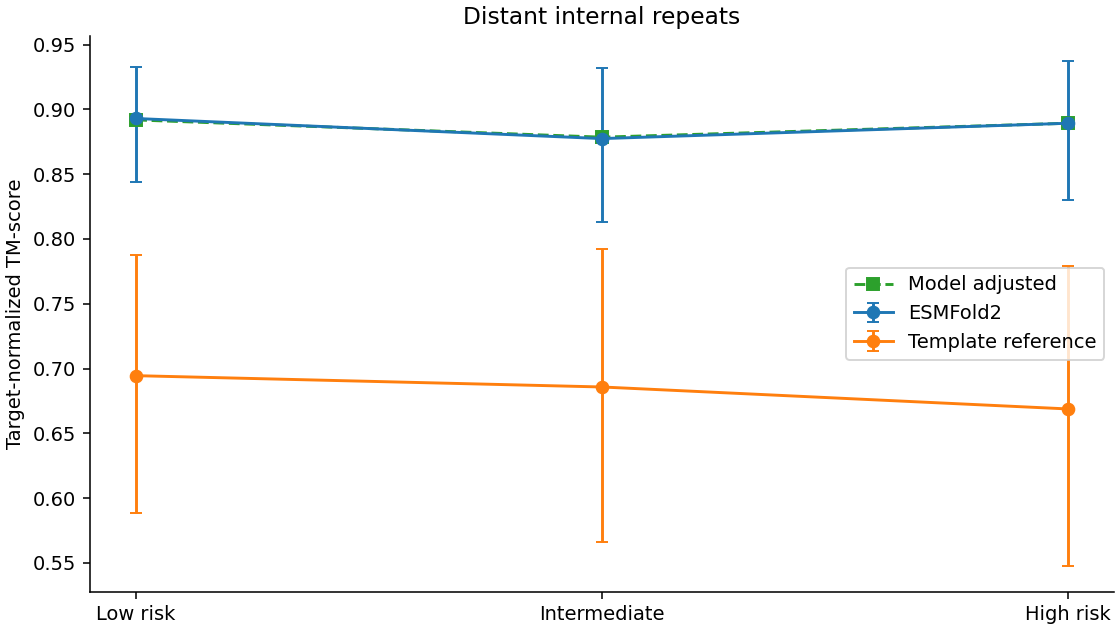

In [10]:
def standardize(frame,columns):
    matrix=frame[columns].to_numpy(float);sd=matrix.std(axis=0);sd[sd==0]=1;return (matrix-matrix.mean(axis=0))/sd
def hc3_fit(x,y):
    inverse=np.linalg.pinv(x.T@x);beta=inverse@x.T@y;residual=y-x@beta;leverage=np.einsum('ij,jk,ik->i',x,inverse,x)
    variance=(residual/np.maximum(1-leverage,1e-8))**2;covariance=inverse@(x.T@(x*variance[:,None]))@inverse
    return beta,np.sqrt(np.maximum(0,np.diag(covariance)))
model_matrix=measurements.pivot(index='set_id',columns='axis_level',values='tm_model').reindex(columns=LEVELS).to_numpy()
reference_matrix=measurements.pivot(index='set_id',columns='axis_level',values='tm_reference').reindex(columns=LEVELS).to_numpy()
if not np.isfinite(model_matrix).all() or not np.isfinite(reference_matrix).all():raise ValueError('Incomplete matched outcomes')
rng=np.random.default_rng(20260716)
if AXIS in ['entropy','dominance']:
    level_draws=[rng.integers(0,len(model_matrix),size=(10000,len(model_matrix))) for _ in LEVELS]
    model_draws=np.column_stack([model_matrix[ids,j].mean(axis=1) for j,ids in enumerate(level_draws)])
    reference_draws=np.column_stack([reference_matrix[ids,j].mean(axis=1) for j,ids in enumerate(level_draws)])
else:
    draws=rng.integers(0,len(model_matrix),size=(10000,len(model_matrix)))
    model_draws=model_matrix[draws].mean(axis=1);reference_draws=reference_matrix[draws].mean(axis=1)
curve_rows=[]
for label,matrix,bootstrap in [('ESMFold2',model_matrix,model_draws),('Template reference',reference_matrix,reference_draws)]:
    for i,level in enumerate(LEVELS):
        lo,hi=np.quantile(bootstrap[:,i],[.025,.975]);curve_rows.append({'model':label,'level':level,'n':len(matrix),'mean':float(matrix[:,i].mean()),'lo':float(lo),'hi':float(hi)})
curves=pd.DataFrame(curve_rows)
x_controls=standardize(measurements,controls);axis_values=standardize(measurements,[axis_column])
beta,se=hc3_fit(np.column_stack([np.ones(len(measurements)),axis_values,x_controls]),measurements.tm_model.to_numpy())
dummies=np.column_stack([measurements.axis_level.eq(level).astype(float) for level in LEVELS[1:]])
level_beta,level_se=hc3_fit(np.column_stack([np.ones(len(measurements)),dummies,x_controls]),measurements.tm_model.to_numpy())
adjusted_means=np.r_[level_beta[0],level_beta[0]+level_beta[1:3]]
contrast=float(model_matrix[:,2].mean()-model_matrix[:,0].mean());interval=np.quantile(model_draws[:,2]-model_draws[:,0],[.025,.975])
reference_degradation=float(reference_matrix[:,0].mean()-reference_matrix[:,2].mean());model_degradation=-contrast
paired=(model_draws[:,0]-model_draws[:,2])-(reference_draws[:,0]-reference_draws[:,2])
summary={'risk_minus_control':contrast,'ci95':interval.tolist(),'standardized_axis_coefficient':float(beta[1]),'hc3_se':float(se[1]),'coefficient_ci95':[float(beta[1]-1.96*se[1]),float(beta[1]+1.96*se[1])],'adjusted_level_means':dict(zip(LEVELS,adjusted_means)),'model_degradation':model_degradation,'reference_degradation':reference_degradation,'model_minus_reference_degradation':model_degradation-reference_degradation,'paired_ci95':np.quantile(paired,[.025,.975]).tolist()}
confounds=measurements.groupby('axis_level')[controls].mean();display(curves);display(summary);display(confounds)
fig,ax=plt.subplots(figsize=(8,4.5),layout='constrained')
for label,part in curves.groupby('model',sort=False):ax.errorbar(range(3),part['mean'],yerr=[part['mean']-part.lo,part.hi-part['mean']],marker='o',capsize=3,label=label)
ax.plot(range(3),adjusted_means,'s--',label='Model adjusted');ax.set(xticks=range(3),xticklabels=['Low risk','Intermediate','High risk'],ylabel='Target-normalized TM-score',title=TITLE);ax.legend();ax.spines[['top','right']].set_visible(False)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
looks=[]
if AXIS=='entropy':
    for n in [40,60,80]:
        part=model_matrix[:n];reference_part=reference_matrix[:n];local_rng=np.random.default_rng(20260716);ids=[local_rng.integers(0,n,size=(10000,n)) for _ in LEVELS];bs=np.column_stack([part[index,j].mean(axis=1) for j,index in enumerate(ids)])
        looks.append({'per_level_n':n,'risk_minus_control':float(part[:,2].mean()-part[:,0].mean()),'ci_low':float(np.quantile(bs[:,2]-bs[:,0],.025)),'ci_high':float(np.quantile(bs[:,2]-bs[:,0],.975)),'reference_degradation':float(reference_part[:,0].mean()-reference_part[:,2].mean())})
    display(pd.DataFrame(looks));print('The decision uses the complete80-per-level calculation; interim summaries do not select targets or change the final threshold.')
screen_rows=[]
if AXIS=='screens':
    for feature,direction in [('distant_repeat4_coverage',-1),('normalized_sequence_entropy',1),('max_residue_fraction',-1),('chain_multiplicity',-1),('cysteine_fraction',-1),('gly_pro_fraction',-1),('hydrophobic_fraction',-1),('sequence_length',-1),('low_complexity_fraction',-1),('net_charge_proxy',-1)]:
        values=measurements[feature];constant=values.nunique()<2;result=stats.spearmanr(values,measurements.tm_model) if not constant else None
        rho=float(result.statistic) if result is not None else np.nan;p=float(result.pvalue) if result is not None else np.nan
        disposition='constant input feature' if constant else 'directionally aligned discovery association' if rho*direction>0 else 'opposite the proposed decline'
        screen_rows.append({'feature':feature,'n':len(values),'rho':rho,'p':p,'expected_sign':direction,'disposition':disposition})
    screens=pd.DataFrame(screen_rows);display(screens)
    fig,axes=plt.subplots(2,5,figsize=(16,6),layout='constrained')
    for ax,row in zip(axes.ravel(),screen_rows):ax.scatter(measurements[row['feature']],measurements.tm_model,s=14);ax.set(xlabel=row['feature'],ylabel='TM-score');ax.tick_params(labelsize=7)
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


## 6. What the agent decided, and why

Use the calculated effect, uncertainty and adjusted direction; show discovery screens as candidate dispositions rather than completed independent experiments.


In [11]:
expected_coefficient=1 if AXIS=='entropy' else -1
supported=bool(contrast<=-.10 and interval[1]<0 and np.all(np.diff(adjusted_means)<0) and beta[1]*expected_coefficient>0)
if AXIS=='screens':decision='Use the displayed discovery associations to retain directionally aligned candidates; constant or opposite-direction features do not support the proposed weakness. These are candidate screens, not confirmatory axis results.'
elif supported:decision='The measured decline meets the0.10 effect, interval and adjusted-direction requirements in this explicitly selected panel.'
else:decision='The measured curve does not jointly meet the0.10 effect, interval and adjusted-direction requirements in this explicitly selected panel.'
print(decision)
print('Same-example reference:', 'model declines at least as much' if model_degradation>=reference_degradation else 'template reference declines more')
output=ROOT/('test-'+str(TEST).zfill(2));output.mkdir(parents=True,exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False);measurements.to_csv(output/'scores.csv',index=False);curves.to_csv(output/'curves.csv',index=False);confounds.to_csv(output/'control_means.csv')
(output/'statistics.json').write_text(json.dumps(summary,indent=2));pd.DataFrame(looks).to_csv(output/'information_looks.csv',index=False);pd.DataFrame(screen_rows).to_csv(output/'candidate_screens.csv',index=False)
receipt={'analysis_id':'esmfold2-codex-r2/test-'+str(TEST).zfill(2),'completed':True,'host':socket.gethostname(),'source_candidates':len(entity_ids),'coordinate_eligible_pool':len(pool),'evaluated_targets':len(features),'selection_seed':20260716,'query':query,'excluded_source_entities':len(excluded_candidates),'foldbench_revision':FOLDBENCH_REVISION,'foldbench_sources':exclusion_sources,'paper_example_source':{'doi':'10.64898/2026.06.03.729735','figure':'S14','pdb_ids':sorted(PAPER_FIGURE_S14_IDS)},'search_binding':search_binding,'new_inference_executed':inferred_target_count>0,'new_inference_targets':inferred_target_count,'verified_prediction_targets':len(features),'model_settings':settings,'checkpoint':checkpoint_signature,'bootstrap_unit':'independent targets within each level' if AXIS in ['entropy','dominance'] else 'matched input sets','control_columns':controls,'decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


The measured curve does not jointly meet the0.10 effect, interval and adjusted-direction requirements in this explicitly selected panel.
Same-example reference: template reference declines more


7679